In [1]:
import pandas as pd

xl = pd.ExcelFile(
    r'C:\Users\scyya\OneDrive\Desktop\SheSync\data\PCOS_data_without_infertility.xlsx',
    engine='openpyxl'
)
print(xl.sheet_names)

['Instructions', 'Full_new']


In [2]:
import os

# This prints where Python is currently looking
print("Current directory:", os.getcwd())

# This checks if the data folder exists and lists what's inside
data_path = r'C:\Users\scyya\OneDrive\Desktop\SheSync\data'
if os.path.exists(data_path):
    print("\nFiles in data folder:")
    print(os.listdir(data_path))
else:
    print("\nData folder NOT found at that path")
    # Let's search for it
    desktop = r'C:\Users\scyya\OneDrive\Desktop'
    print("\nFolders on Desktop:")
    print(os.listdir(desktop))

Current directory: C:\Users\scyya\OneDrive\Desktop\SheSync

Files in data folder:
['PCOS_data_without_infertility.xlsx', 'PCOS_infertility.csv']


In [3]:
import os
print(os.listdir(r'C:\Users\scyya\OneDrive\Desktop\SheSync\data'))

['PCOS_data_without_infertility.xlsx', 'PCOS_infertility.csv']


In [4]:
import pandas as pd

xl = pd.ExcelFile(
    r'C:\Users\scyya\OneDrive\Desktop\SheSync\data\PCOS_data_without_infertility.xlsx',
    engine='openpyxl'
)
print(xl.sheet_names)

['Instructions', 'Full_new']


In [5]:
df = pd.read_excel(
    r'C:\Users\scyya\OneDrive\Desktop\SheSync\data\PCOS_data_without_infertility.xlsx',
    sheet_name='Full_new',
    engine='openpyxl'
)

print("✅ Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

✅ Dataset loaded successfully!
Shape: (541, 45)


,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 44
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,1.0,0,110,80,3,3,18.0,18.0,8.5,NaN
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0.0,0,120,70,3,5,15.0,14.0,3.7,NaN
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1.0,0,120,80,13,15,18.0,20.0,10.0,NaN
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0.0,0,120,70,2,2,15.0,14.0,7.5,NaN
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0.0,0,120,80,3,4,16.0,14.0,7.0,NaN


In [6]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Sl. No                      0
Patient File No.            0
PCOS (Y/N)                  0
 Age (yrs)                  0
Weight (Kg)                 0
Height(Cm)                  0
BMI                         0
Blood Group                 0
Pulse rate(bpm)             0
RR (breaths/min)            0
Hb(g/dl)                    0
Cycle(R/I)                  0
Cycle length(days)          0
Marraige Status (Yrs)       1
Pregnant(Y/N)               0
No. of aborptions           0
  I   beta-HCG(mIU/mL)      0
II    beta-HCG(mIU/mL)      0
FSH(mIU/mL)                 0
LH(mIU/mL)                  0
FSH/LH                      0
Hip(inch)                   0
Waist(inch)                 0
Waist:Hip Ratio             0
TSH (mIU/L)                 0
AMH(ng/mL)                  0
PRL(ng/mL)                  0
Vit D3 (ng/mL)              0
PRG(ng/mL)                  0
RBS(mg/dl)                  0
Weight gain(Y/N)            0
hair growth(Y/N)            0
Skin darkenin

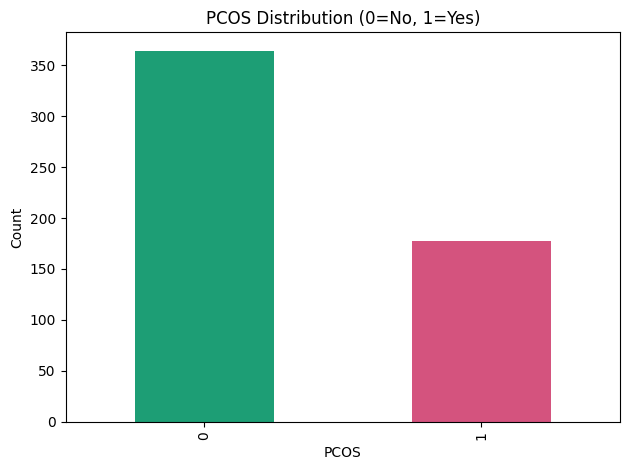

In [7]:
import matplotlib.pyplot as plt

df['PCOS (Y/N)'].value_counts().plot(
    kind='bar', 
    color=['#1D9E75','#D4537E']
)
plt.title('PCOS Distribution (0=No, 1=Yes)')
plt.xlabel('PCOS')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [8]:
# Drop junk column
df = df.drop(columns=['Unnamed: 44'])

# Fill the 2 missing values
df['Marraige Status (Yrs)'] = df['Marraige Status (Yrs)'].fillna(df['Marraige Status (Yrs)'].median())
df['Fast food (Y/N)'] = df['Fast food (Y/N)'].fillna(df['Fast food (Y/N)'].mode()[0])

print("✅ Cleaned! New shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

✅ Cleaned! New shape: (541, 44)
Remaining missing values: 0


In [9]:
X = df.drop(columns=['PCOS (Y/N)', 'Sl. No', 'Patient File No.'])
y = df['PCOS (Y/N)']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:", y.value_counts().to_dict())

Features shape: (541, 41)
Target shape: (541,)

Target values: {0: 364, 1: 177}


In [10]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Convert all columns to numeric, bad values become NaN
X_clean = X.apply(pd.to_numeric, errors='coerce')

# Fill any new NaNs with column median
X_clean = X_clean.fillna(X_clean.median())

print("Any remaining nulls:", X_clean.isnull().sum().sum())
print("Shape:", X_clean.shape)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42
)

# Apply SMOTE
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("✅ SMOTE applied!")
print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_sm.value_counts().to_dict())

Any remaining nulls: 0
Shape: (541, 41)
✅ SMOTE applied!
Before SMOTE: {0: 287, 1: 145}
After SMOTE: {1: 287, 0: 287}


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Train the model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_sm, y_train_sm)

# Predict on test set
y_pred_rf = rf_model.predict(X_test)

# Results
print("✅ Random Forest Results:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.2f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_rf):.2f}")
print("\nFull Report:")
print(classification_report(y_test, y_pred_rf))

✅ Random Forest Results:
Accuracy:  0.83
F1 Score:  0.71

Full Report:
              precision    recall  f1-score   support

           0       0.88      0.87      0.88        77
           1       0.70      0.72      0.71        32

    accuracy                           0.83       109
   macro avg       0.79      0.79      0.79       109
weighted avg       0.83      0.83      0.83       109



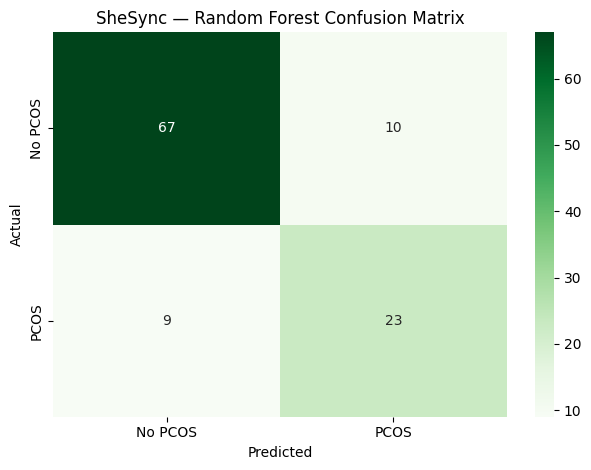

In [12]:
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No PCOS','PCOS'],
            yticklabels=['No PCOS','PCOS'])
plt.title('SheSync — Random Forest Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

In [13]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_sm, y_train_sm)

y_pred_xgb = xgb_model.predict(X_test)

print("✅ XGBoost Results:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_xgb):.2f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_xgb):.2f}")
print("\nFull Report:")
print(classification_report(y_test, y_pred_xgb))

✅ XGBoost Results:
Accuracy:  0.83
F1 Score:  0.73

Full Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88        77
           1       0.71      0.75      0.73        32

    accuracy                           0.83       109
   macro avg       0.80      0.81      0.80       109
weighted avg       0.84      0.83      0.84       109



           Model  Accuracy  F1 Score
0  Random Forest  0.825688  0.707692
1        XGBoost  0.834862  0.727273


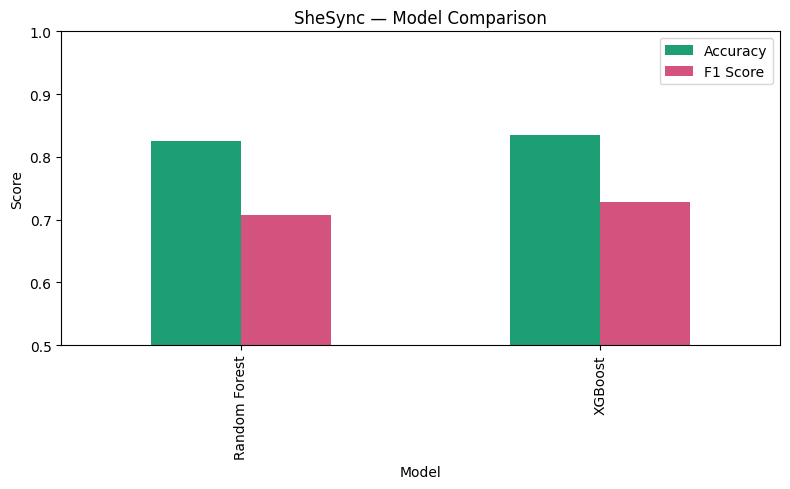

In [14]:
results = {
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [accuracy_score(y_test, y_pred_rf), 
                 accuracy_score(y_test, y_pred_xgb)],
    'F1 Score': [f1_score(y_test, y_pred_rf), 
                 f1_score(y_test, y_pred_xgb)]
}

results_df = pd.DataFrame(results)
print(results_df)

results_df.plot(x='Model', kind='bar', figsize=(8,5), 
                color=['#1D9E75','#D4537E'])
plt.title('SheSync — Model Comparison')
plt.ylabel('Score')
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

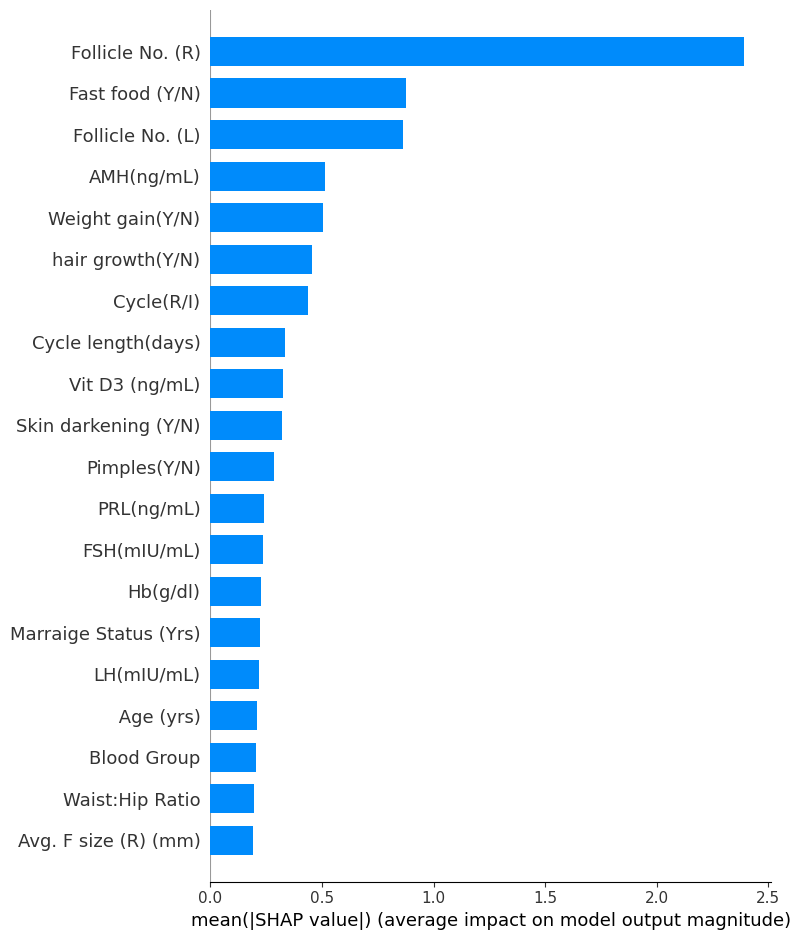

In [15]:
import shap

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

# Summary plot - shows most important features
shap.summary_plot(shap_values, X_test, 
                  plot_type="bar",
                  title="SheSync — Top Features for PCOS Detection")

In [16]:
import joblib

joblib.dump(rf_model, r'C:\Users\scyya\OneDrive\Desktop\SheSync\models\pcos_rf_model.pkl')
joblib.dump(xgb_model, r'C:\Users\scyya\OneDrive\Desktop\SheSync\models\pcos_xgb_model.pkl')
joblib.dump(X_clean.columns.tolist(), r'C:\Users\scyya\OneDrive\Desktop\SheSync\models\feature_names.pkl')

print("✅ Models saved successfully!")
print("Saved: pcos_rf_model.pkl")
print("Saved: pcos_xgb_model.pkl")
print("Saved: feature_names.pkl")

✅ Models saved successfully!
Saved: pcos_rf_model.pkl
Saved: pcos_xgb_model.pkl
Saved: feature_names.pkl
